# Fase 2 Minería de Datos NYC311

## 1 Qué vamos a hacer

Este notebook continúa el trabajo de la Fase 1. No toma los datos directamente de la capa RAW: parte de una vista analítica construida sobre `DW_NYC311`, exportada como `resultados.csv`.

Seguiremos el proceso KDD. Primero revisamos y preparamos los datos; después aplicamos un Árbol de Decisión para clasificar demora alta y K-Means para agrupar perfiles operativos. Finalmente evaluamos las métricas y traducimos los resultados a acciones posibles.

La cadena de trazabilidad es: NYC Open Data → ETL Fase 1 → `raw.Solicitud` → `stg.Solicitud` → `DW_NYC311` → `mining.vw_dataset_fase2` → CSV → pandas y scikit-learn.


## 2 Cargar el dataset

`pandas` es una biblioteca de Python para trabajar con tablas. Al cargar el CSV obtenemos un `DataFrame`, que puede entenderse como una tabla con filas y columnas.

El archivo se exportó desde SQL Server usando punto y coma como separador. Por eso se usa `sep=";"`. La celda busca el archivo en las rutas habituales del proyecto y también permite cargarlo en Google Colab.

Al final se muestra `df.shape`, que responde cuántas filas y columnas se cargaron, y `df.head()`, que permite revisar algunos registros sin modificar los datos.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay, silhouette_score,
)
from sklearn.cluster import KMeans

sns.set_theme(style="whitegrid", context="notebook")
candidates = [
    Path("resultados.csv"),
    Path("tmp/data/resultados.csv"),
    Path("../resultados.csv"),
    Path("../tmp/data/resultados.csv"),
    Path("/content/resultados.csv"),
]
DATA_PATH = next((path for path in candidates if path.exists()), candidates[0])
if not DATA_PATH.exists():
    try:
        from google.colab import files
    except ImportError as error:
        searched = "\n".join(f"- {path.resolve()}" for path in candidates[:-1])
        raise FileNotFoundError(
            "No se encontró resultados.csv. Rutas revisadas:\n"
            f"{searched}\n"
            "Coloque el archivo en tmp/data/resultados.csv o junto al notebook."
        ) from error
    uploaded = files.upload()
    if not uploaded:
        raise FileNotFoundError("No se seleccionó resultados.csv en Google Colab.")
    DATA_PATH = Path(next(iter(uploaded)))

df = pd.read_csv(DATA_PATH, sep=";")
print(f"Fuente: {DATA_PATH}")
print(f"Dimensiones: {df.shape}")
display(df.head())

Fuente: resultados.csv
Dimensiones: (1293816, 13)


,codigo_solicitud,agency,complaint_type,borough,status,open_data_channel_type,anio,mes,dia_semana,minutos_resolucion,demora_alta,latitude,longitude
0,68514296,NYPD,Noise - Residential,BRONX,Closed,ONLINE,2026,4,4,99.0,0.0,40.838409,-73.911061
1,68518432,NYPD,Noise - Residential,BRONX,Closed,ONLINE,2026,4,4,71.0,0.0,40.837259,-73.903567
2,68518436,NYPD,Noise - Residential,BRONX,Closed,ONLINE,2026,4,4,8.0,0.0,40.836941,-73.903744
3,68520014,NYPD,Noise - Residential,BRONX,Closed,ONLINE,2026,4,4,66.0,0.0,40.837259,-73.903567
4,68521556,NYPD,Noise - Residential,MANHATTAN,Closed,PHONE,2026,4,4,12.0,0.0,40.718899,-73.994639


## 3 Entender el dataset

Antes de modelar comprobamos el contrato de columnas de la vista de minería. `df.shape` muestra el tamaño del dataset, `df.dtypes` muestra el tipo de cada columna y `df.info()` permite ver rápidamente tipos y valores no nulos cuando se ejecuta de forma interactiva.

También revisamos nulos, duplicados y cardinalidad. La cardinalidad indica cuántos valores distintos tiene una categoría, por ejemplo cuántas agencias o tipos de reclamo aparecen. Esto ayuda a anticipar cómo se transformarán las columnas categóricas.


In [ ]:
required_columns = [
    "codigo_solicitud", "agency", "complaint_type", "borough", "status",
    "open_data_channel_type", "anio", "mes", "dia_semana",
    "minutos_resolucion", "demora_alta", "latitude", "longitude",
]
missing_columns = sorted(set(required_columns) - set(df.columns))
unexpected_columns = sorted(set(df.columns) - set(required_columns))
if missing_columns or unexpected_columns:
    raise ValueError(
        f"Contrato de columnas inválido. Faltantes={missing_columns}; "
        f"inesperadas={unexpected_columns}"
    )
df = df[required_columns].copy()
print("Tipos de datos:")
df.info()
display(df.dtypes.to_frame("dtype"))
print("Valores nulos:")
display(df.isna().sum().to_frame("nulos").query("nulos > 0"))
print(f"Duplicados completos: {df.duplicated().sum():,}")
print("Cardinalidad de variables categóricas:")
display(df[["agency", "complaint_type", "borough", "status", "open_data_channel_type"]].nunique())

Tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1293816 entries, 0 to 1293815
Data columns (total 13 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   codigo_solicitud        1293816 non-null  int64  
 1   agency                  1293816 non-null  object 
 2   complaint_type          1293816 non-null  object 
 3   borough                 1293816 non-null  object 
 4   status                  1293816 non-null  object 
 5   open_data_channel_type  1293816 non-null  object 
 6   anio                    1293816 non-null  int64  
 7   mes                     1293816 non-null  int64  
 8   dia_semana              1293816 non-null  int64  
 9   minutos_resolucion      1230737 non-null  float64
 10  demora_alta             1230737 non-null  float64
 11  latitude                1262803 non-null  float64
 12  longitude               1262803 non-null  float64
dtypes: float64(4), int64(4), object(5)
memory

,dtype
codigo_solicitud,int64
agency,object
complaint_type,object
borough,object
status,object
open_data_channel_type,object
anio,int64
mes,int64
dia_semana,int64
minutos_resolucion,float64


Valores nulos:


,nulos
minutos_resolucion,63079
demora_alta,63079
latitude,31013
longitude,31013


Duplicados completos: 0
Cardinalidad de variables categóricas:


,0
agency,15
complaint_type,189
borough,6
status,7
open_data_channel_type,5


## 4 Revisar calidad de datos

Un valor nulo no siempre es un error. En este dataset, `minutos_resolucion` puede estar vacío cuando una solicitud todavía no tiene cierre registrado. No lo reemplazamos por un promedio porque eso inventaría un tiempo que no se ha observado.

En la siguiente celda contamos esos casos por estado y comprobamos que no existan duplicados completos. Las solicitudes sin tiempo final se conservan para describir el rezago, pero no se usan para entrenar la clasificación de demora alta.

## 5 Construir demora alta

Un percentil indica la posición de un valor dentro de una distribución. El percentil 75, o P75, deja aproximadamente 75% de los tiempos observados por debajo o igual al corte y 25% por encima.

NYC Open Data no entrega una etiqueta llamada `demora_alta`. Por eso la construimos con los tiempos resueltos del período abril a julio de 2026. El resultado es P75 = 4,329 minutos. No es un estándar universal ni vino de NYC Open Data, scikit-learn o el docente: se calculó con nuestros datos.

`minutos_resolucion` es una variable continua. `demora_alta` la discretiza en dos clases: 0 para tiempo menor o igual al P75 y 1 para tiempo superior. Los valores sin cierre quedan sin clasificar.


In [ ]:
null_resolution_by_status = (
    df.loc[df["minutos_resolucion"].isna(), "status"]
    .value_counts(dropna=False)
    .rename("solicitudes_sin_resolucion")
)
display(null_resolution_by_status.to_frame())

resolved = df["minutos_resolucion"].dropna()
p75 = float(resolved.quantile(0.75))
target_recomputed = pd.Series(pd.NA, index=df.index, dtype="Int64")
has_resolution = df["minutos_resolucion"].notna()
target_recomputed.loc[has_resolution] = (
    df.loc[has_resolution, "minutos_resolucion"].gt(p75).astype("int64")
)
assert df["demora_alta"].astype("Int64").equals(target_recomputed)
df["demora_alta"] = target_recomputed
print(f"P75 de minutos_resolucion: {p75:,.0f} minutos")
display(df["demora_alta"].value_counts(dropna=False).sort_index().rename("solicitudes").to_frame())

,solicitudes_sin_resolucion
status,
In Progress,45104
Open,14366
Pending,1674
Assigned,1241
Started,678
Unspecified,13
Closed,3


P75 de minutos_resolucion: 4,329 minutos


,solicitudes
demora_alta,
0,923081
1,307656
<NA>,63079


Las gráficas siguientes permiten revisar visualmente la distribución del tiempo de resolución y el volumen de nulos. Se usan para entender los datos; no cambian ninguna observación.


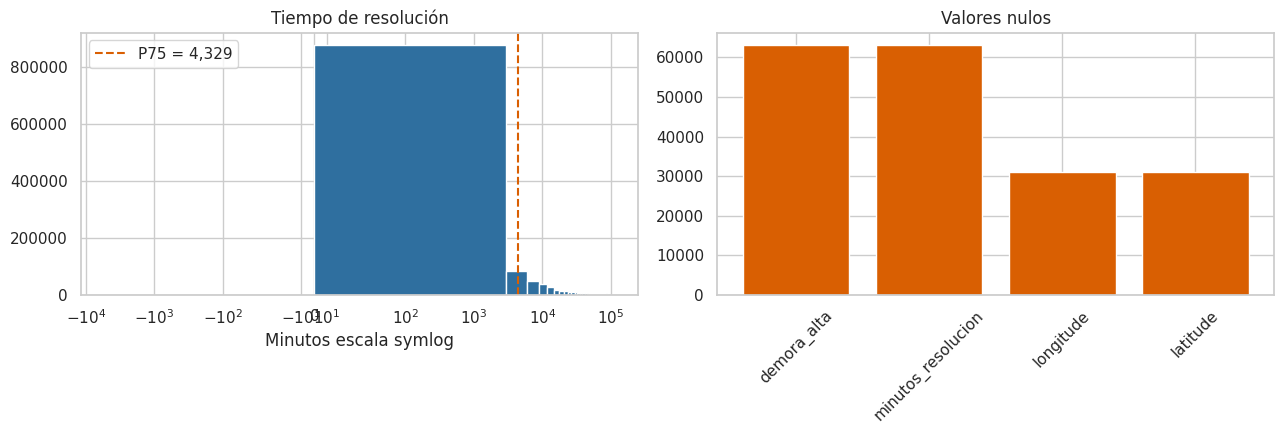

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(resolved, bins=80, color="#2f6f9f")
axes[0].axvline(p75, color="#d95f02", linestyle="--", label=f"P75 = {p75:,.0f}")
axes[0].set_xscale("symlog", linthresh=60)
axes[0].set_title("Tiempo de resolución")
axes[0].set_xlabel("Minutos escala symlog")
axes[0].legend()
nulls = df.isna().sum().sort_values(ascending=False)
nulls = nulls[nulls > 0]
axes[1].bar(nulls.index, nulls.values, color="#d95f02")
axes[1].set_title("Valores nulos")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 6 Seleccionar variables

Para clasificar una solicitud usamos `agency`, `complaint_type`, `borough`, `open_data_channel_type`, `mes` y `dia_semana`. Estas variables están disponibles como contexto de la solicitud y no incluyen su tiempo final.

Se excluye `minutos_resolucion` por **data leakage**. La fuga de información ocurre cuando se entrega al modelo un dato que, en un escenario real, todavía no estaría disponible al hacer la predicción. Aquí no puede ser predictor porque `demora_alta` se construyó precisamente a partir de `minutos_resolucion`.

También quedan fuera `status`, el identificador, el año y las coordenadas. `status` puede reflejar información posterior al registro; el código no tiene significado predictivo, el año no varía en el período y las coordenadas se reservan para otro análisis.

## 7 Separar X e y

`X` es la tabla de variables que el modelo puede observar. `y` es la respuesta que queremos predecir: `demora_alta`. Solo se incluyen filas donde esa respuesta existe, es decir, las 1,230,737 solicitudes con tiempo de resolución.

## 8 Train Test

Usamos 80% de las solicitudes clasificables para entrenamiento y 20% para prueba. Entrenamiento significa que el modelo aprende patrones con esos datos. Prueba significa que reservamos datos para verificar si el modelo generaliza a casos que no vio durante el ajuste.

`stratify=y` conserva aproximadamente la proporción 75/25 entre clase normal y demora alta en ambos grupos. `random_state=42` permite repetir exactamente la misma partición.

## 9 OneHotEncoder

El modelo necesita números, pero no debemos convertir `agency=NYPD` en un número mayor o menor que `agency=HPD`. `OneHotEncoder` crea columnas binarias: una columna indica si la agencia es NYPD y otra si es HPD. Así representa categorías sin inventar un orden numérico.

## 10 Pipeline

Un `Pipeline` une el preprocesamiento y el modelo. De esta forma, el mismo `OneHotEncoder` se aplica durante el entrenamiento y durante una predicción, sin depender de pasos manuales diferentes.

## 11 Árbol baseline

Un Árbol de Decisión toma decisiones sucesivas para separar clases. En cada nodo busca una división que deje grupos más puros. Su impureza puede medirse con Gini: si un nodo contiene casi una sola clase, su Gini se acerca a 0.

`max_depth` limita cuántos niveles puede crecer el árbol. `min_samples_leaf` evita hojas creadas con muy pocos casos. El baseline usa profundidad 6 y al menos 100 casos por hoja; será el punto de comparación para el ajuste posterior.

## 12 Evaluación baseline

Las métricas responden preguntas distintas sobre las solicitudes con demora alta. Accuracy es el porcentaje total de aciertos. Precision pregunta cuántas alertas emitidas sí eran demora alta. Recall pregunta cuántas demoras altas reales fueron detectadas. F1 combina precision y recall. ROC-AUC evalúa qué tan bien el modelo ordena el riesgo usando probabilidades.

La matriz de confusión separa verdaderos positivos, falsos positivos, verdaderos negativos y falsos negativos. En este proyecto interesan especialmente los falsos negativos: demoras reales que el modelo no alertó.

## 13 GridSearchCV

Un hiperparámetro es una configuración del modelo que se define antes de entrenar. `GridSearchCV` prueba combinaciones de hiperparámetros y elige la mejor según F1. Aquí evalúa 3 valores de profundidad, 3 mínimos por hoja y 2 pesos de clase: 18 combinaciones.

La validación cruzada divide los datos de entrenamiento en tres partes. En cada ronda entrena con dos partes y valida con la restante; luego rota la parte validada. Por eso se realizan 18 × 3 = 54 ajustes. Optimizamos F1 porque equilibra precisión y recall en una clase de demora alta menos frecuente.


In [ ]:
categorical_features = ["agency", "complaint_type", "borough", "open_data_channel_type"]
numeric_features = ["mes", "dia_semana"]
model_features = categorical_features + numeric_features
classification_df = df.loc[df["demora_alta"].notna()].copy()
X = classification_df[model_features]
y = classification_df["demora_alta"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
transformer = ColumnTransformer(
    [("categoricas", OneHotEncoder(handle_unknown="ignore"), categorical_features)],
    remainder="passthrough",
)

def make_pipeline(class_weight=None, max_depth=None, min_samples_leaf=1):
    return Pipeline([
        ("preprocesamiento", transformer),
        ("modelo", DecisionTreeClassifier(
            class_weight=class_weight,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            random_state=42,
        )),
    ])

baseline = make_pipeline(max_depth=6, min_samples_leaf=100)
baseline.fit(X_train, y_train)
RUN_GRID_SEARCH = False  # Use False durante una demostración corta.
if not RUN_GRID_SEARCH:
    optimized = make_pipeline(
        class_weight="balanced", max_depth=15, min_samples_leaf=50
    )
    optimized.fit(X_train, y_train)
    grid = None
    print("Modo demostración: se usan los mejores parámetros ya validados.")
else:
    grid = GridSearchCV(
        make_pipeline(),
        {
            "modelo__max_depth": [6, 10, 15],
            "modelo__min_samples_leaf": [50, 100, 250],
            "modelo__class_weight": [None, "balanced"],
        },
        scoring="f1", cv=3, n_jobs=-1, verbose=2,
    )
    grid.fit(X_train, y_train)
    optimized = grid.best_estimator_
    print("Mejores parámetros:", grid.best_params_)
    print(f"Mejor F1 de validación cruzada: {grid.best_score_:.6f}")

Modo demostración: se usan los mejores parámetros ya validados.


## 14 Árbol optimizado

El modelo optimizado usa `class_weight="balanced"`, que aumenta el peso relativo de la clase minoritaria. El trade-off observado es esperado: Recall sube para dejar menos demoras sin alerta, mientras Precision baja porque se generan más alertas preventivas. Por eso el árbol se propone como filtro para revisión humana, no como decisión automática.

La siguiente celda calcula las métricas de baseline y modelo optimizado sobre el conjunto de prueba apartado. También muestra la matriz de confusión y el reporte de clasificación.


In [ ]:
def evaluate(model, X_eval, y_eval):
    pred = model.predict(X_eval)
    proba = model.predict_proba(X_eval)[:, 1]
    return {
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred, zero_division=0),
        "F1": f1_score(y_eval, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, proba),
        "Matriz": confusion_matrix(y_eval, pred),
        "pred": pred,
        "proba": proba,
    }

baseline_results = evaluate(baseline, X_test, y_test)
optimized_results = evaluate(optimized, X_test, y_test)
comparison = pd.DataFrame(
    {"Baseline": {k: baseline_results[k] for k in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]},
     "Optimizado": {k: optimized_results[k] for k in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]}}
)
display(comparison.style.format("{:.6f}"))
print("Matriz optimizada:")
print(optimized_results["Matriz"])
print(classification_report(y_test, optimized_results["pred"], digits=6))

,Baseline,Optimizado
Accuracy,0.869814,0.868738
Precision,0.837910,0.666261
Recall,0.594140,0.951537
F1,0.695277,0.783747
ROC-AUC,0.921671,0.952276


Matriz optimizada:
[[155289  29328]
 [  2982  58549]]
              precision    recall  f1-score   support

           0   0.981159  0.841141  0.905771    184617
           1   0.666261  0.951537  0.783747     61531

    accuracy                       0.868738    246148
   macro avg   0.823710  0.896339  0.844759    246148
weighted avg   0.902442  0.868738  0.875268    246148



## 15 Importancia de variables

La importancia de una variable indica cuánto la utiliza este árbol para separar las clases. No demuestra que esa variable cause una demora. En particular, que `agency` tenga alta importancia predictiva no permite afirmar que una agencia sea la causa del tiempo de resolución.

La siguiente celda recupera `feature_importances_`, agrupa las columnas creadas por OneHotEncoder y muestra la matriz de confusión y la curva ROC del modelo optimizado.


,source,importance
0,agency,0.799478
2,complaint_type,0.162652
4,mes,0.012577
3,dia_semana,0.011187
1,borough,0.010341
5,open_data_channel_type,0.003765


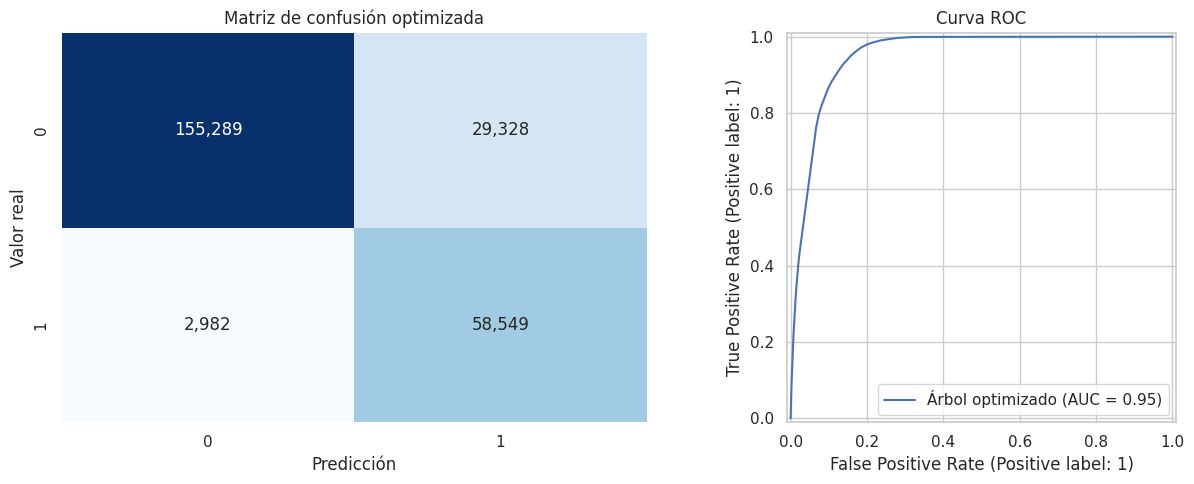

In [ ]:
feature_names = optimized.named_steps["preprocesamiento"].get_feature_names_out()
importances = optimized.named_steps["modelo"].feature_importances_
importance_detail = pd.DataFrame({"feature": feature_names, "importance": importances})
importance_detail["feature"] = importance_detail["feature"].str.split("__").str[-1]
importance_detail["source"] = importance_detail["feature"]
for column in categorical_features:
    importance_detail.loc[importance_detail["feature"].str.startswith(column + "_"), "source"] = column
importance_by_source = (
    importance_detail.groupby("source", as_index=False)["importance"]
    .sum().sort_values("importance", ascending=False)
)
display(importance_by_source.style.format({"importance": "{:.6f}"}))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(optimized_results["Matriz"], annot=True, fmt=",", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Matriz de confusión optimizada")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Valor real")
RocCurveDisplay.from_predictions(y_test, optimized_results["proba"], ax=axes[1], name="Árbol optimizado")
axes[1].set_title("Curva ROC")
plt.tight_layout()
plt.show()

## 16 Preparar K Means

K-Means no se aplica directamente a los 1,293,816 tickets. Primero resumimos muchas solicitudes en un perfil definido por `agency + complaint_type + borough`. Cada perfil conserva cuántas solicitudes tiene, su mediana de resolución, el porcentaje de demora y el porcentaje sin resolución.

Así pasamos de muchas filas individuales a 912 perfiles. Se conservan 487 con al menos 100 solicitudes y 480 que tienen métricas suficientes para el clustering. Este filtro evita construir grupos a partir de combinaciones demasiado pequeñas.

## 17 log1p

`log1p` aplica el logaritmo de `1 + valor`. Se usa en el número de solicitudes y la mediana de resolución para comprimir valores muy grandes y sesgados sin cambiar el orden entre perfiles. Un perfil de gran volumen sigue siendo mayor que uno pequeño, pero deja de dominar únicamente por su escala numérica.

## 18 StandardScaler

K-Means mide distancias. `StandardScaler` transforma las variables para que sean comparables en escala. Sin esta normalización, una variable numéricamente grande, como la cantidad de solicitudes, podría dominar la distancia y ocultar el efecto de los porcentajes.


In [ ]:
profiles = (
    df.groupby(["agency", "complaint_type", "borough"], dropna=False)
    .agg(
        solicitudes=("codigo_solicitud", "count"),
        resueltas=("minutos_resolucion", "count"),
        mediana_resolucion=("minutos_resolucion", "median"),
        promedio_resolucion=("minutos_resolucion", "mean"),
        porcentaje_demora=("demora_alta", "mean"),
    ).reset_index()
)
profile_count_before = len(profiles)
profiles["porcentaje_sin_resolucion"] = 1 - profiles["resueltas"] / profiles["solicitudes"]
profiles = profiles.loc[profiles["solicitudes"] >= 100].copy()
profile_count_after = len(profiles)
profiles = profiles.dropna(subset=["mediana_resolucion", "porcentaje_demora"]).copy()
profiles["log_solicitudes"] = np.log1p(profiles["solicitudes"])
profiles["log_mediana_resolucion"] = np.log1p(profiles["mediana_resolucion"])
cluster_features = [
    "log_solicitudes", "log_mediana_resolucion",
    "porcentaje_demora", "porcentaje_sin_resolucion",
]
scaler = StandardScaler()
scaled_profiles = scaler.fit_transform(profiles[cluster_features])
print(f"Perfiles originales: {profile_count_before}")
print(f"Perfiles con mínimo 100 solicitudes: {profile_count_after}")
print(f"Perfiles finales para K-Means: {len(profiles)}")

Perfiles originales: 912
Perfiles con mínimo 100 solicitudes: 487
Perfiles finales para K-Means: 480


## 19 Seleccionar K

`K` es el número de grupos que queremos buscar. Un cluster es un grupo de perfiles parecidos y su centroide es el punto promedio que representa al grupo. K-Means asigna cada perfil al centroide más cercano y actualiza esos centros hasta reducir las distancias dentro de los clusters.

La Inertia suma las distancias cuadradas de los perfiles a su centroide; valores más bajos indican grupos más compactos, aunque siempre tiende a bajar cuando se agregan más clusters. Silhouette compara qué tan parecido es un perfil a su propio grupo frente a otros grupos; valores mayores indican mejor separación.

Se prueba K entre 2 y 8. Elegimos K=3 porque obtuvo el Silhouette más alto, 0.421321. Es una separación útil pero moderada: los grupos pueden solaparse y deben interpretarse como perfiles de exploración, no como categorías absolutas.

## 20 K Means final

`fit_predict` ajusta K-Means y devuelve el cluster asignado a cada perfil. Después nombramos los tres clusters según sus métricas observadas para facilitar una interpretación de negocio.


In [ ]:
k_metrics = []
for k in range(2, 9):
    candidate = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = candidate.fit_predict(scaled_profiles)
    k_metrics.append({
        "K": k,
        "Inertia": candidate.inertia_,
        "Silhouette": silhouette_score(scaled_profiles, labels),
    })
k_metrics = pd.DataFrame(k_metrics)
display(k_metrics.style.format({"Inertia": "{:.6f}", "Silhouette": "{:.6f}"}))
final_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
profiles["cluster"] = final_kmeans.fit_predict(scaled_profiles)
raw_cluster_summary = profiles.groupby("cluster").agg(
    perfiles=("cluster", "size"),
    solicitudes=("solicitudes", "sum"),
    mediana_resolucion=("mediana_resolucion", "median"),
    porcentaje_demora=("porcentaje_demora", "mean"),
    porcentaje_sin_resolucion=("porcentaje_sin_resolucion", "mean"),
)
order = raw_cluster_summary.sort_values("mediana_resolucion").index.tolist()
cluster_names = {
    order[0]: "Resolución rápida y baja demora",
    order[1]: "Resolución prolongada y alta demora",
    order[2]: "Rezago crítico y alta proporción sin resolver",
}
profiles["cluster_nombre"] = profiles["cluster"].map(cluster_names)
cluster_summary = raw_cluster_summary.reset_index()
cluster_summary["cluster_nombre"] = cluster_summary["cluster"].map(cluster_names)
display(cluster_summary.style.format({
    "porcentaje_demora": "{:.2%}",
    "porcentaje_sin_resolucion": "{:.2%}",
    "mediana_resolucion": "{:.0f}",
}))

,K,Inertia,Silhouette
0,2,1135.841936,0.384586
1,3,772.452946,0.421321
2,4,604.326328,0.367590
3,5,455.908397,0.365767
4,6,371.829120,0.376295
5,7,316.814870,0.389565
6,8,284.059070,0.380476


,cluster,perfiles,solicitudes,mediana_resolucion,porcentaje_demora,porcentaje_sin_resolucion,cluster_nombre
0,0,206,899050,143,8.94%,1.32%,Resolución rápida y baja demora
1,1,245,351275,11376,71.09%,6.09%,Resolución prolongada y alta demora
2,2,29,29467,33150,79.10%,82.72%,Rezago crítico y alta proporción sin resolver


Las gráficas siguientes muestran cómo cambia Inertia y Silhouette al variar K, y dónde quedan los perfiles operativos. El tamaño de cada punto representa el volumen de solicitudes del perfil.


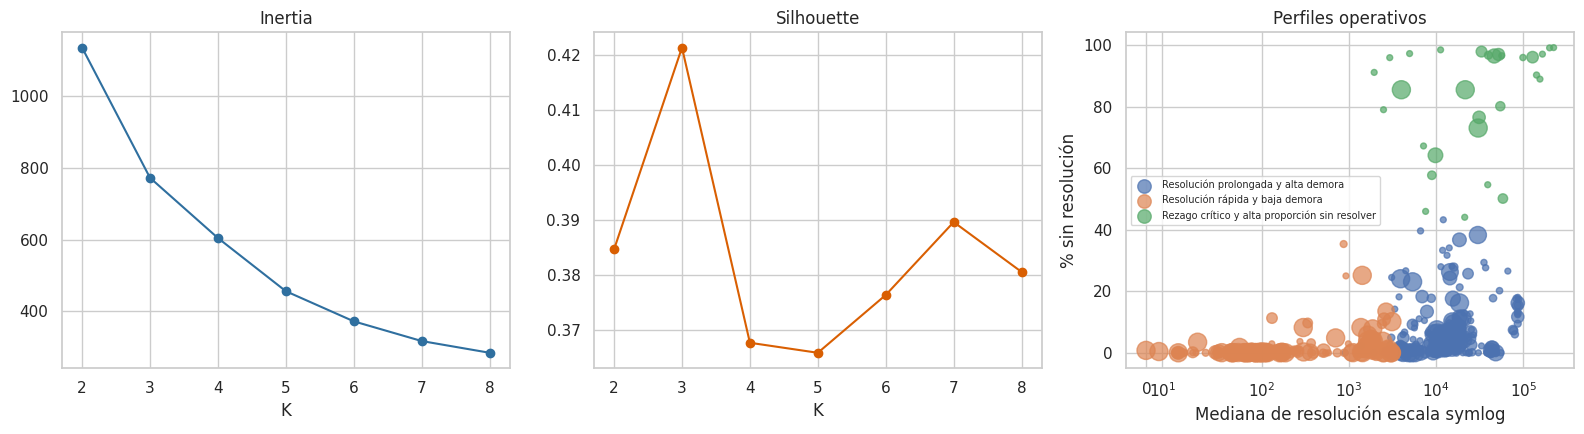

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(k_metrics["K"], k_metrics["Inertia"], marker="o", color="#2f6f9f")
axes[0].set_title("Inertia")
axes[0].set_xlabel("K")
axes[1].plot(k_metrics["K"], k_metrics["Silhouette"], marker="o", color="#d95f02")
axes[1].set_title("Silhouette")
axes[1].set_xlabel("K")
for name, group in profiles.groupby("cluster_nombre"):
    axes[2].scatter(
        group["mediana_resolucion"], group["porcentaje_sin_resolucion"] * 100,
        s=np.clip(group["solicitudes"] / 20, 18, 170), alpha=.7, label=name,
    )
axes[2].set_xscale("symlog", linthresh=60)
axes[2].set_title("Perfiles operativos")
axes[2].set_xlabel("Mediana de resolución escala symlog")
axes[2].set_ylabel("% sin resolución")
axes[2].legend(fontsize=7)
plt.tight_layout()
plt.show()

In [ ]:
profiles.to_csv('ResultadosKMeans.csv', index=False, sep=';')
from google.colab import files
files.download('ResultadosKMeans.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 21 Interpretación

Los tres perfiles encontrados son: resolución rápida, resolución prolongada y rezago crítico. La resolución rápida concentra 899,050 solicitudes, con mediana de 143 minutos y 8.94% de demora. La resolución prolongada reúne 351,275 solicitudes, una mediana de 11,376 minutos y 71.09% de demora. El rezago crítico reúne 29,467 solicitudes, con 79.10% de demora y 82.72% sin resolución observada.

El árbol ayuda a priorizar alertas de demora. K-Means ayuda a decidir dónde investigar procesos. La recomendación operativa es revisar los perfiles de alto volumen en resolución prolongada y auditar primero los estados y cierres del rezago crítico.

## 22 Conclusiones y limitaciones

El análisis identifica patrones predictivos y perfiles de operación, pero no prueba causalidad. El período cubre abril a julio de 2026 y no representa un año completo. Las solicitudes abiertas no se imputan como resueltas.

El P75 fue definido como una regla descriptiva global del período abril-julio de 2026 antes del experimento predictivo. En una implementación prospectiva, el umbral debería calcularse exclusivamente con el histórico disponible antes del período que se desea predecir.

Para reproducir el análisis, ejecute las celdas en orden con `resultados.csv` disponible en `tmp/data/`. Use `RUN_GRID_SEARCH=True` para repetir los 54 ajustes y `False` para una demostración con los parámetros ya validados.
